In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

print("Environment is working!")

Environment is working!


In [2]:
from pathlib import Path

data_path = Path("../data/CIFAKE")

train_real = data_path / "train" / "REAL"
train_fake = data_path / "train" / "FAKE"

print("REAL images:", len(list(train_real.iterdir())))
print("FAKE images:", len(list(train_fake.iterdir())))

REAL images: 50000
FAKE images: 50000


Image size: (32, 32)
Image mode: RGB


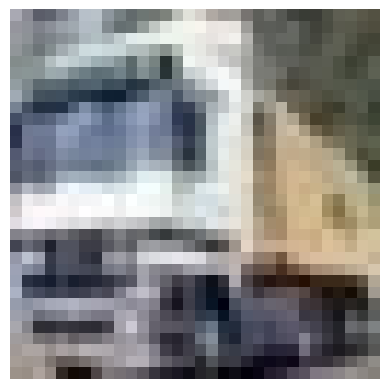

In [3]:
from PIL import Image
import matplotlib.pyplot as plt

image_path = next(train_real.iterdir())
image = Image.open(image_path)

print("Image size:", image.size)
print("Image mode:", image.mode)

plt.imshow(image)
plt.axis('off')
plt.show()

Turn Image into Numbers

In [4]:
import numpy as np

image_array = np.array(image)

print("Array shape:", image_array.shape)
print("Data type:", image_array.dtype)
print("First pixel:", image_array[0, 0])

Array shape: (32, 32, 3)
Data type: uint8
First pixel: [169 169 179]


32 × 32       → image dimensions
3             → RGB channels
[169 169 179]   → one pixel's RGB values

An image is just a NumPy array containing numbers.

In [6]:
print("Red:", image_array[0, 0, 0])
print("Green:", image_array[0, 0, 1])
print("Blue:", image_array[0, 0, 2])

Red: 169
Green: 169
Blue: 179


### Lession 2: Grayscale, RGB, and Image Statistics

Original mode: RGB
Grayscale mode: L


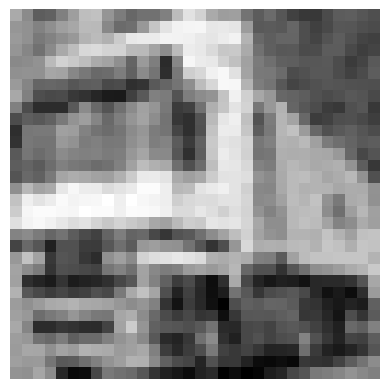

In [7]:
# RBG --> Grayscale conversion

gray_image = image.convert("L")

print("Original mode:", image.mode)
print("Grayscale mode:", gray_image.mode)

plt.imshow(gray_image, cmap="gray")
plt.axis("off")
plt.show()

In [8]:
gray_array = np.array(gray_image)

print("RGB shape:", image_array.shape)
print("Grayscale shape:", gray_array.shape)

RGB shape: (32, 32, 3)
Grayscale shape: (32, 32)


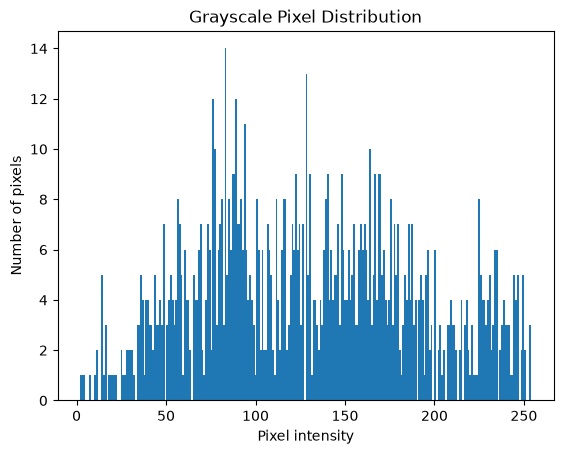

In [9]:
plt.hist(gray_array.ravel(), bins=256)
plt.xlabel("Pixel intensity")
plt.ylabel("Number of pixels")
plt.title("Grayscale Pixel Distribution")
plt.show()

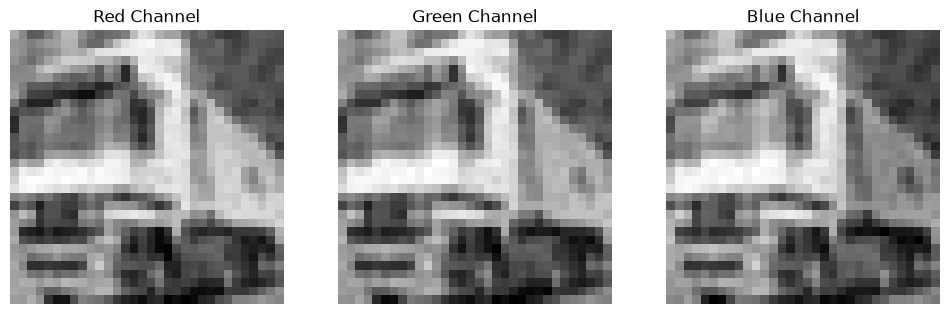

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(12, 4))

axes[0].imshow(image_array[:, :, 0], cmap="gray")
axes[0].set_title("Red Channel")
axes[0].axis("off")

axes[1].imshow(image_array[:, :, 1], cmap="gray")
axes[1].set_title("Green Channel")
axes[1].axis("off")

axes[2].imshow(image_array[:, :, 2], cmap="gray")
axes[2].set_title("Blue Channel")
axes[2].axis("off")

plt.show()

In [11]:
print("Mean brightness:", gray_array.mean())
print("Minimum brightness:", gray_array.min())
print("Maximum brightness:", gray_array.max())
print("Standard deviation:", gray_array.std())

Mean brightness: 130.2998046875
Minimum brightness: 2
Maximum brightness: 254
Standard deviation: 59.99981249938914


An image is a dataset of pixels. Each pixel contains numerical information, and image processing examines or changes those numbers to reveal useful patterns.

### Lesson 3 - Filters & Convolution

Clean image
     ↓
tiny random dots
     ↓
noisy image

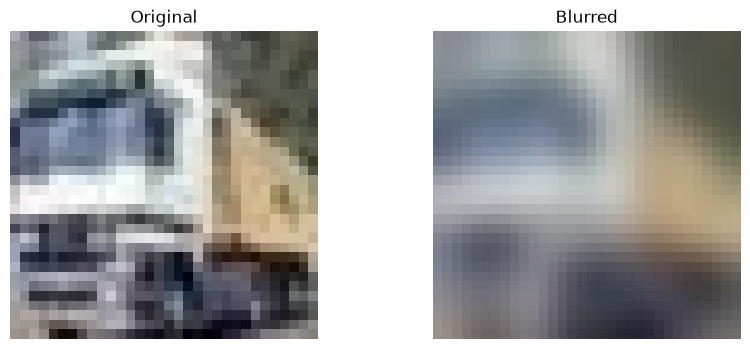

In [42]:
from PIL import ImageFilter

blurred_image = image.filter(ImageFilter.GaussianBlur(radius=2))

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(image)
plt.title("Original")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(blurred_image)
plt.title("Blurred")
plt.axis("off")

plt.show()

In [43]:
pip install opencv-python

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.1.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [44]:
import cv2

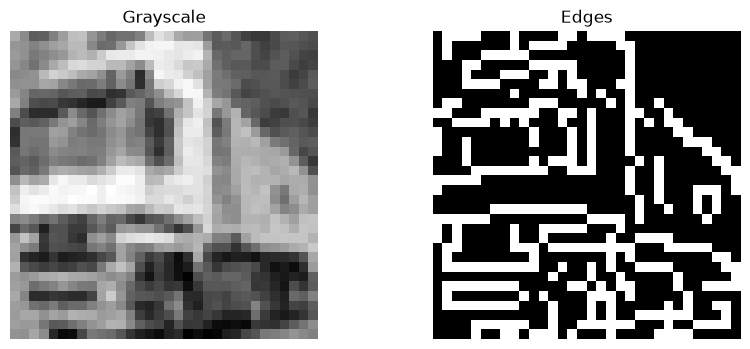

In [45]:
image_cv = np.array(image)

gray_cv = cv2.cvtColor(image_cv, cv2.COLOR_RGB2GRAY)

edges = cv2.Canny(gray_cv, 150, 250)

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(gray_cv, cmap="gray")
plt.title("Grayscale")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(edges, cmap="gray")
plt.title("Edges")
plt.axis("off")

plt.show()

In [46]:
pip freeze > requirements.txt

Note: you may need to restart the kernel to use updated packages.


### Lession 4 - Thersholding

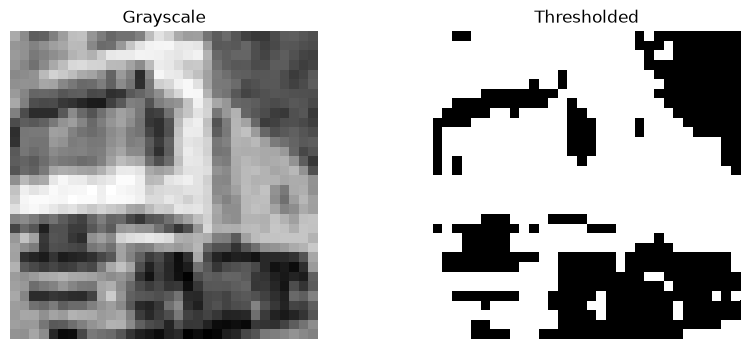

In [65]:
threshold_value = 100

_, thresholded = cv2.threshold(
    gray_cv,
    threshold_value,
    255,
    cv2.THRESH_BINARY
)

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(gray_cv, cmap="gray")
plt.title("Grayscale")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(thresholded, cmap="gray")
plt.title("Thresholded")
plt.axis("off")

plt.show()

In [48]:
for value in [50, 100, 150, 200]:
    _, result = cv2.threshold(
        gray_cv,
        value,
        255,
        cv2.THRESH_BINARY
    )

    white_pixels = np.sum(result == 255)
    total_pixels = result.size
    percentage = (white_pixels / total_pixels) * 100

    print(
        f"Threshold {value}: "
        f"{percentage:.2f}% white pixels"
    )

Threshold 50: 91.11% white pixels
Threshold 100: 63.57% white pixels
Threshold 150: 37.99% white pixels
Threshold 200: 14.06% white pixels


### Lession 5 - Texture & Image Statistics

In [49]:
red = image_array[:, :, 0]
green = image_array[:, :, 1]
blue = image_array[:, :, 2]

print("Red mean:", red.mean())
print("Green mean:", green.mean())
print("Blue mean:", blue.mean())

print("Red std:", red.std())
print("Green std:", green.std())
print("Blue std:", blue.std())

Red mean: 130.3427734375
Green mean: 130.3251953125
Blue mean: 130.2744140625
Red std: 61.64064430072129
Green std: 60.2846333773892
Blue std: 58.4135971305894


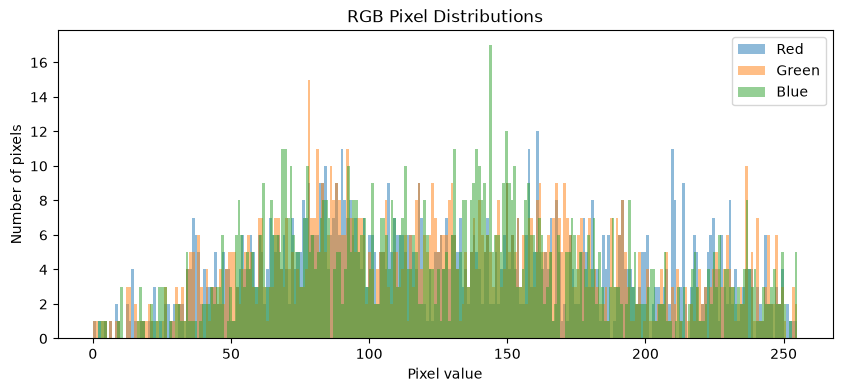

In [50]:
plt.figure(figsize=(10, 4))

plt.hist(red.ravel(), bins=256, alpha=0.5, label="Red")
plt.hist(green.ravel(), bins=256, alpha=0.5, label="Green")
plt.hist(blue.ravel(), bins=256, alpha=0.5, label="Blue")

plt.xlabel("Pixel value")
plt.ylabel("Number of pixels")
plt.title("RGB Pixel Distributions")
plt.legend()
plt.show()

In [51]:
gray_array = np.array(gray_image)

horizontal_diff = np.abs(
    gray_array[:, 1:].astype(np.int16) -
    gray_array[:, :-1].astype(np.int16)
)

print("Average horizontal difference:", horizontal_diff.mean())

Average horizontal difference: 21.748991935483872


In [52]:
print("Image shape:", image_array.shape)
print("Mean:", gray_array.mean())
print("Std:", gray_array.std())
print("Texture variation:", horizontal_diff.mean())

Image shape: (32, 32, 3)
Mean: 130.2998046875
Std: 59.99981249938914
Texture variation: 21.748991935483872


### Lession 6 - From Features to Pattern Recognition

In [53]:
def extract_features(image_path):
    image = Image.open(image_path).convert("RGB")
    image_array = np.array(image)

    gray = np.array(image.convert("L"))

    # Basic colour statistics
    red = image_array[:, :, 0]
    green = image_array[:, :, 1]
    blue = image_array[:, :, 2]

    # Texture variation
    horizontal_diff = np.abs(
        gray[:, 1:].astype(np.int16) -
        gray[:, :-1].astype(np.int16)
    )

    return {
        "red_mean": red.mean(),
        "green_mean": green.mean(),
        "blue_mean": blue.mean(),
        "gray_mean": gray.mean(),
        "gray_std": gray.std(),
        "texture": horizontal_diff.mean()
    }

In [54]:
features = extract_features(image_path)

print(features)

{'red_mean': np.float64(130.3427734375), 'green_mean': np.float64(130.3251953125), 'blue_mean': np.float64(130.2744140625), 'gray_mean': np.float64(130.2998046875), 'gray_std': np.float64(59.99981249938914), 'texture': np.float64(21.748991935483872)}


In [55]:
import pandas as pd

rows = []

# Use a small sample while learning
real_images = list(train_real.iterdir())[:100]
fake_images = list(train_fake.iterdir())[:100]

for path in real_images:
    features = extract_features(path)
    features["label"] = 0
    rows.append(features)

for path in fake_images:
    features = extract_features(path)
    features["label"] = 1
    rows.append(features)

feature_df = pd.DataFrame(rows)

feature_df.head()

,red_mean,green_mean,blue_mean,gray_mean,gray_std,texture,label
0,130.342773,130.325195,130.274414,130.299805,59.999812,21.748992,0
1,92.188477,102.393555,115.953125,100.883789,56.763362,13.614919,0
2,120.540039,152.875977,85.214844,135.495117,43.073724,17.303427,0
3,77.915039,71.681641,61.402344,72.375000,55.989257,9.877016,0
4,99.888672,83.250000,57.906250,85.330078,32.691599,12.180444,0


In [66]:
feature_df.groupby("label")[[
    "gray_mean",
    "gray_std",
    "texture"
]].mean()

,gray_mean,gray_std,texture
label,,,
0,119.238359,49.936795,14.374667
1,110.422451,51.407063,14.090484


### Lesson 7 - Your First REAL vs FAKE Classifier

In [68]:
X = feature_df.drop("label", axis=1)
y = feature_df["label"]

print("Features:")
print(X.head())

print("\nLabels:")
print(y.head())

Features:
     red_mean  green_mean   blue_mean   gray_mean   gray_std    texture
0  130.342773  130.325195  130.274414  130.299805  59.999812  21.748992
1   92.188477  102.393555  115.953125  100.883789  56.763362  13.614919
2  120.540039  152.875977   85.214844  135.495117  43.073724  17.303427
3   77.915039   71.681641   61.402344   72.375000  55.989257   9.877016
4   99.888672   83.250000   57.906250   85.330078  32.691599  12.180444

Labels:
0    0
1    0
2    0
3    0
4    0
Name: label, dtype: int64


In [58]:
# Split the data

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 160
Testing samples: 40


In [59]:
# Train a simple model

from sklearn.linear_model import LogisticRegression

model = LogisticRegression(max_iter=1000)

model.fit(X_train, y_train)

,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use i

In [60]:
y_pred = model.predict(X_test)

print("Predictions:")
print(y_pred)

Predictions:
[1 0 1 1 0 1 1 1 1 1 1 0 1 1 0 1 1 0 0 1 0 1 0 1 1 1 1 1 0 1 1 0 1 1 1 1 0
 1 1 1]


In [61]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print(f"Accuracy : {accuracy:.3f}")
print(f"Precision: {precision:.3f}")
print(f"Recall   : {recall:.3f}")
print(f"F1-score : {f1:.3f}")

Accuracy : 0.575
Precision: 0.552
Recall   : 0.800
F1-score : 0.653


In [ ]:
cm = confusion_matrix(y_test, y_pred)

print(cm)

[[ 7 13]
 [ 4 16]]


: 

In [63]:
results = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": y_pred
})

results.head(20)

,Actual,Predicted
0,0,1
1,1,0
2,1,1
3,1,1
4,0,0
5,1,1
6,0,1
7,1,1
8,1,1
9,0,1


In [64]:
print(pd.crosstab(
    results["Actual"],
    results["Predicted"],
    rownames=["Actual"],
    colnames=["Predicted"]
))

Predicted  0   1
Actual          
0          7  13
1          4  16
